# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [ ]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [2]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,704,99,52,104,177,55,10,210,32,24,166,219,657,215,73,3,2,187,194
1,288,96,47,103,215,69,10,200,33,23,147,220,598,200,73,6,6,187,194
2,42,94,49,87,137,54,11,158,43,20,162,178,366,186,75,5,5,183,194
3,770,80,44,68,120,53,8,151,45,19,146,170,333,190,80,4,16,180,185
4,504,97,46,94,209,67,10,195,34,22,147,224,573,194,70,0,14,188,197
5,762,90,44,69,152,64,7,135,49,18,145,165,272,162,75,3,2,187,191
6,388,94,47,85,333,138,49,155,43,19,155,320,354,187,135,12,9,188,196
7,96,89,42,80,151,62,6,144,46,19,139,166,308,170,74,17,13,185,189
8,186,91,42,81,193,69,5,169,38,20,137,184,434,156,68,3,23,198,204
9,802,89,44,80,191,66,6,162,40,20,143,189,396,180,66,13,11,194,199


Methods `describe` and `info` deliver some useful information.

In [3]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,423.730419,93.788707,44.932605,82.313297,168.843352,61.599271,8.528233,169.400729,40.794171,20.626594,148.200364,189.397086,442.741348,175.218579,72.664845,6.340619,12.744991,188.761384,195.437158
std,242.097269,8.377879,6.097520,15.978550,33.621024,7.972791,4.232912,33.295783,7.748527,2.605599,14.187609,31.619067,177.347031,32.309909,7.684510,4.872705,8.874664,6.102193,7.447270
min,0.000000,76.000000,33.000000,42.000000,104.000000,47.000000,2.000000,114.000000,26.000000,17.000000,118.000000,131.000000,191.000000,109.000000,59.000000,0.000000,0.000000,176.000000,182.000000
25%,206.000000,87.000000,40.000000,70.000000,141.000000,57.000000,7.000000,147.000000,33.000000,19.000000,137.000000,168.000000,319.000000,151.000000,68.000000,2.000000,6.000000,184.000000,190.000000
50%,434.000000,93.000000,44.000000,79.000000,168.000000,61.000000,8.000000,157.000000,43.000000,20.000000,146.000000,179.000000,367.000000,174.000000,72.000000,6.000000,11.000000,189.000000,197.000000
75%,628.000000,100.000000,50.000000,98.000000,194.000000,65.000000,10.000000,200.000000,46.000000,23.000000,160.000000,218.000000,600.000000,198.000000,76.000000,9.000000,19.000000,193.000000,201.000000
max,844.000000,119.000000,58.000000,112.000000,333.000000,138.000000,52.000000,262.000000,59.000000,28.000000,182.000000,320.000000,998.000000,268.000000,135.000000,22.000000,39.000000,204.000000,211.000000


In [4]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

Сначала проверим наши данные на наличие дубликатов

In [5]:
X_train_pd.duplicated().sum()

np.int64(0)

Так как в дальнейшем буду использоваться классические методы, чувствительные к масштабу признаков, отнормируем наши данные

In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Дополнительно посмотрим на распределение целевой переменной

In [7]:
target_pd = pd.DataFrame(target, columns=['target'])
print(target_pd['target'].value_counts())

target
bus     218
saab    217
opel    212
van     199
Name: count, dtype: int64


В данных нет выраженного дисбаланса классов

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [8]:
! pip install scikit-plot

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

import scipy

scipy.interp = np.interp
np.in1d = np.isin

from scikitplot.metrics import plot_roc

cross_val = GridSearchCV(
    estimator=LogisticRegression(
        multi_class='multinomial',
        solver='saga',
        max_iter=500,
        tol=1e-3,
        random_state=42
    ),
    param_grid={
        "C": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100],
    },
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)


cross_val.fit(X_train_scaled, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=500,
                                          multi_class='multinomial',
                                          random_state=42, solver='saga',
                                          tol=0.001),
             n_jobs=-1,
             param_grid={'C': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

In [23]:
from sklearn.metrics import f1_score, accuracy_score

print("Best params:", cross_val.best_params_)
print("Best F1:", cross_val.best_score_)

best_model = cross_val.best_estimator_

y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

print("Test F1 score:", f1_score(y_test, y_pred, average='macro'))
print("Test Accuracy score:", accuracy_score(y_test, y_pred))

Best params: {'C': 100}
Best F1: 0.7921333549805292
Test F1 score: 0.7896980855793982
Test Accuracy score: 0.7845117845117845


<Axes: title={'center': 'ROC Curves'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

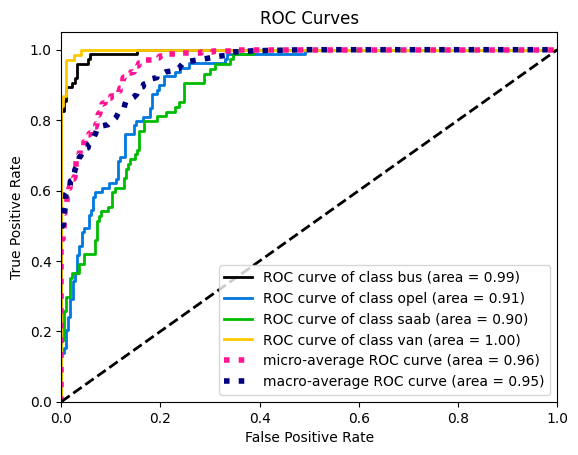

In [24]:
plot_roc(y_test, y_pred_proba)

Получилось добиться F1 score: 0.7897 и Accuracy score: 0.7845 на тесте.
Также показатели метрики ROC-AUC для классов 'van' и 'bus' относительно сильно отличаются от ROC-AUC для классов 'opel' и 'saab'.

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

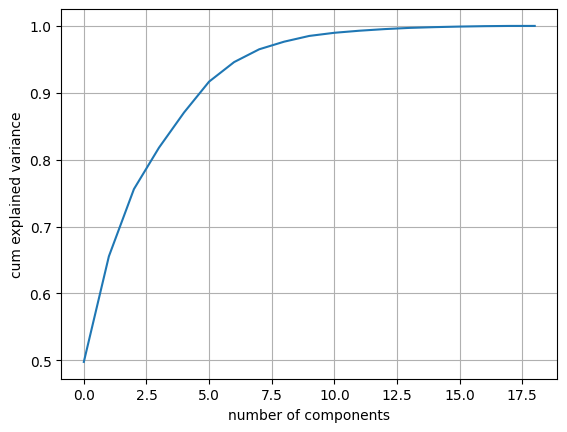

In [20]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA()
pca.fit(X_train_scaled)

plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.grid()
plt.xlabel('number of components')
plt.ylabel('cum explained variance')
plt.show()

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

Было выбрано 9 компонент, так как после удаления большего числа доля объяснённой дисперсии начинает быстро уменьшаться.

PCA применялся к нормализованным данным, так как масштабы у признаков разные.

In [21]:
comp_number = 9

pca = PCA(comp_number)

pca_train = pca.fit_transform(X_train_scaled)
pca_test = pca.transform(X_test_scaled)

**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

import scipy

scipy.interp = np.interp
np.in1d = np.isin

from scikitplot.metrics import plot_roc

cross_val = GridSearchCV(
    estimator=LogisticRegression(
        multi_class='multinomial',
        solver='saga',
        max_iter=500,
        tol=1e-3,
        random_state=42
    ),
    param_grid={
        "C": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100],
    },
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)


cross_val.fit(pca_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


GridSearchCV(cv=5,
             estimator=LogisticRegression(max_iter=500,
                                          multi_class='multinomial',
                                          random_state=42, solver='saga',
                                          tol=0.001),
             n_jobs=-1,
             param_grid={'C': [1e-05, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

In [31]:
from sklearn.metrics import f1_score, accuracy_score

print("Best params:", cross_val.best_params_)
print("Best F1:", cross_val.best_score_)

best_model = cross_val.best_estimator_

y_pred = best_model.predict(pca_test)
y_pred_proba = best_model.predict_proba(pca_test)

print("Test F1 score:", f1_score(y_test, y_pred, average='macro'))
print("Test Accuracy score:", accuracy_score(y_test, y_pred))

Best params: {'C': 10}
Best F1: 0.6567528787801035
Test F1 score: 0.6626592260180721
Test Accuracy score: 0.6666666666666666


<Axes: title={'center': 'ROC Curves'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

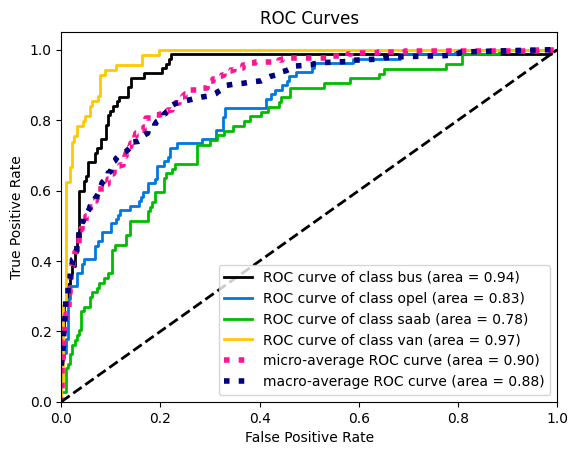

In [27]:
plot_roc(y_test, y_pred_proba)

Как и ожидалось применение pca сильно понизило качество модели, так как количество признаков в исходной обучающей выборке изначально было мало.

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [54]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

cross_val = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid={
        "max_depth": [1, 2, 3, 4, 5, 6],
    },
    scoring="f1_macro",
    cv=5,
    n_jobs=-1
)


cross_val.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [1, 2, 3, 4, 5, 6]}, scoring='f1_macro')

In [35]:
from sklearn.metrics import f1_score, accuracy_score

print("Best params:", cross_val.best_params_)
print("Best F1:", cross_val.best_score_)

best_model = cross_val.best_estimator_

y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)

print("Test F1 score:", f1_score(y_test, y_pred, average='macro'))
print("Test Accuracy score:", accuracy_score(y_test, y_pred))

Best params: {'max_depth': 5}
Best F1: 0.6416091344474777
Test F1 score: 0.6646107857747868
Test Accuracy score: 0.6599326599326599


На тестовой выборке дерево решений показало F1 = 0.6646 и Accuracy = 0.6599.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

In [46]:
from sklearn.ensemble import BaggingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score
from sklearn.pipeline import Pipeline

n_estimators = list(range(2, 101, 5))

models = {
    "Logistic Regression":
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
                    C=100,
                    multi_class='multinomial',
                    solver='saga',
                    max_iter=500,
                    tol=1e-3,
                    random_state=42
                  )
        )
    ]),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42)
}

results = {}

for name, model in models.items():
    f1_scores = []
    accuracy_scores = []

    for n in n_estimators:
        bagging = BaggingClassifier(
            estimator=model,
            n_estimators=n,
            max_samples=1.0,
            bootstrap=True,
            random_state=42,
            n_jobs=-1
        )

        bagging.fit(X_train, y_train)
        y_pred = bagging.predict(X_test)

        f1_scores.append(f1_score(y_test, y_pred, average='macro'))
        accuracy_scores.append(accuracy_score(y_test, y_pred))

    results[name] = {
        "f1": f1_scores,
        "accuracy": accuracy_scores
    }

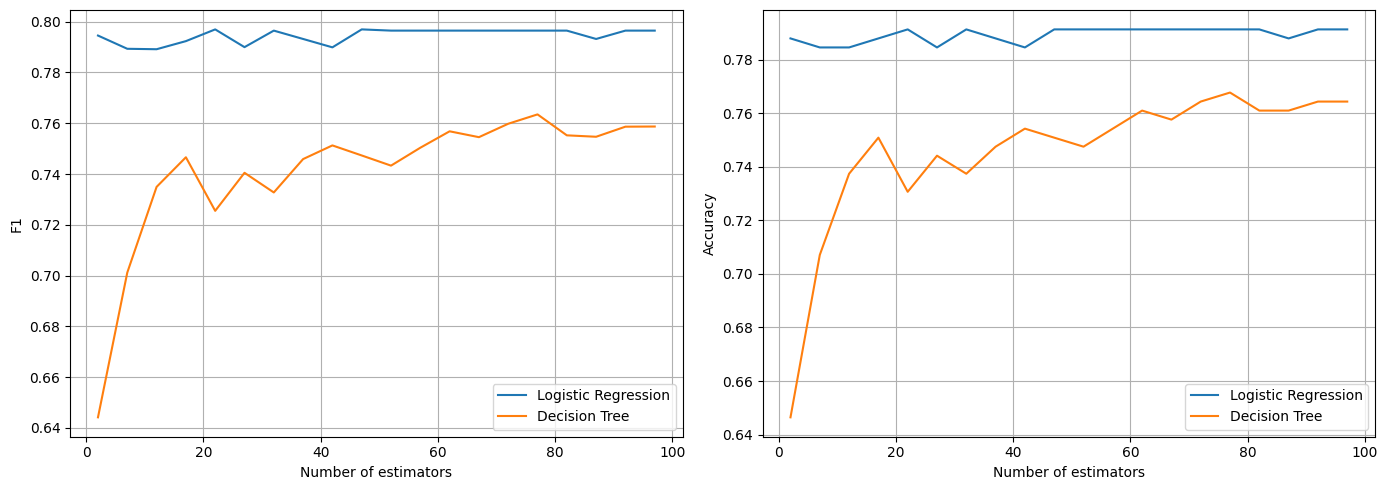

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, scores in results.items():
    axes[0].plot(n_estimators, scores["f1"], label=name)
    axes[1].plot(n_estimators, scores["accuracy"], label=name)

axes[0].set_xlabel("Number of estimators")
axes[0].set_ylabel("F1")
axes[0].legend()
axes[0].grid()

axes[1].set_xlabel("Number of estimators")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [49]:
for name, scores in results.items():
    best_f1_idx = np.argmax(scores["f1"])
    best_acc_idx = np.argmax(scores["accuracy"])

    print(f"\n{name}:")
    print(f"Optimum algorithms number by f1 score: {n_estimators[best_f1_idx]}")
    print(f"Optimum algorithms number by accuracy: {n_estimators[best_acc_idx]}")


Logistic Regression:
Optimum algorithms number by f1 score: 22
Optimum algorithms number by accuracy: 22

Decision Tree:
Optimum algorithms number by f1 score: 77
Optimum algorithms number by accuracy: 77


Оптимальное количество алгоритмов для логистической регрессии - 22, а для дерева решений - 77, так как в этом случае обе модели показали лучшее качество на тесте.

При этом оптимальные параметры, найденные для одного дерева в пункте 2.5 не должны быть оптимальными для всех деревьев в ансамбле. Бэггинг снижает дисперсию ансамбля за счёт усреднения ответов нескольких деревьев, поэтому в данном случае можно использовать более глубокие деревья, чем в одиночном случае.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [65]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

n_estimators = list(range(2, 101, 5))

f1_scores = []
accuracy_scores = []

for n in n_estimators:
    random_forest = RandomForestClassifier(
        n_estimators=n,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )

    random_forest.fit(X_train, y_train)
    y_pred = random_forest.predict(X_test)

    f1_scores.append(f1_score(y_test, y_pred, average='macro'))
    accuracy_scores.append(accuracy_score(y_test, y_pred))

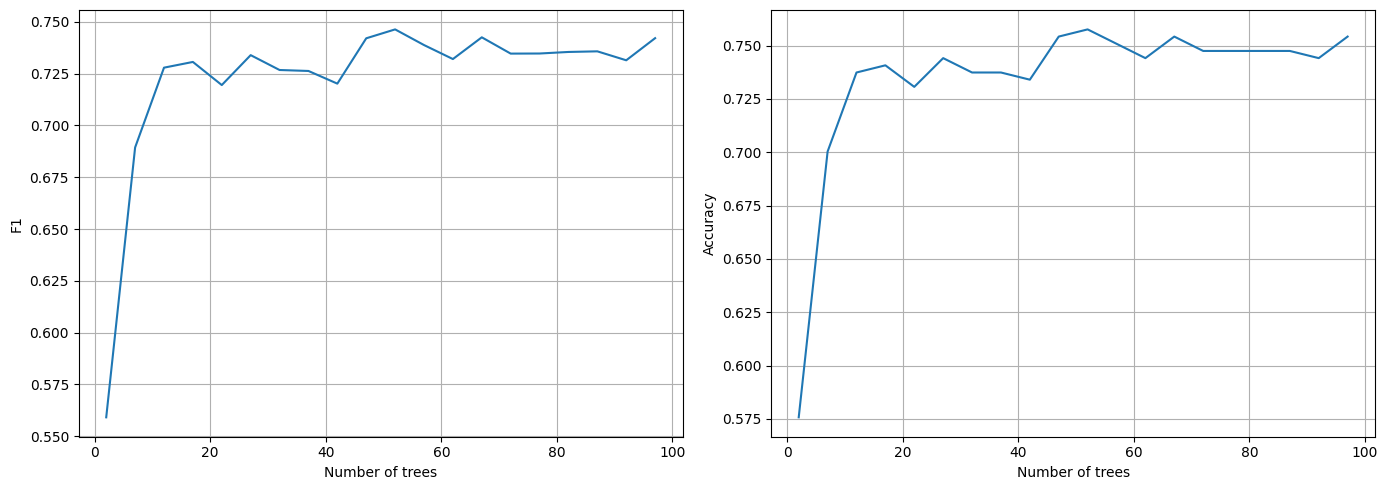

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(n_estimators, f1_scores)
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("F1")
axes[0].grid()

axes[1].plot(n_estimators, accuracy_scores)
axes[1].set_xlabel("Number of trees")
axes[1].set_ylabel("Accuracy")
axes[1].grid()

plt.tight_layout()
plt.show()

In [66]:
best_f1_idx = np.argmax(f1_scores)
best_acc_idx = np.argmax(accuracy_scores)

print(f"Optimum trees number by f1 score: {n_estimators[best_f1_idx]}")
print(f"Optimum trees number by accuracy: {n_estimators[best_acc_idx]}")

Optimum trees number by f1 score: 52
Optimum trees number by accuracy: 52


В данном случае оптимальное количество деревьев равно 52, что отличается от оптимального количества алгоритмов в пункте 2.6

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

In [55]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score

train_parts = np.array_split(
    np.random.RandomState(42).permutation(len(X_train)),
    10
)

models = {
    "Logistic Regression":
    Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=100,
            multi_class='multinomial',
            solver='saga',
            max_iter=500,
            tol=1e-3,
            random_state=42
        ))
    ]),

    "Decision Tree":
    DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest":
    RandomForestClassifier(
        n_estimators=52,
        max_depth=5,
        random_state=42,
        n_jobs=-1
    )
}

results = {}

for name, model in models.items():
    f1_scores = []
    accuracy_scores = []

    for i in range(1, 11):
        idxs = np.concatenate(train_parts[:i])

        X_train_subset = X_train[idxs]
        y_train_subset = y_train[idxs]

        model.fit(X_train_subset, y_train_subset)
        y_pred = model.predict(X_test)

        f1_scores.append(
            f1_score(y_test, y_pred, average='macro')
        )
        accuracy_scores.append(
            accuracy_score(y_test, y_pred)
        )

    results[name] = {
        "f1": f1_scores,
        "accuracy": accuracy_scores
    }

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid t

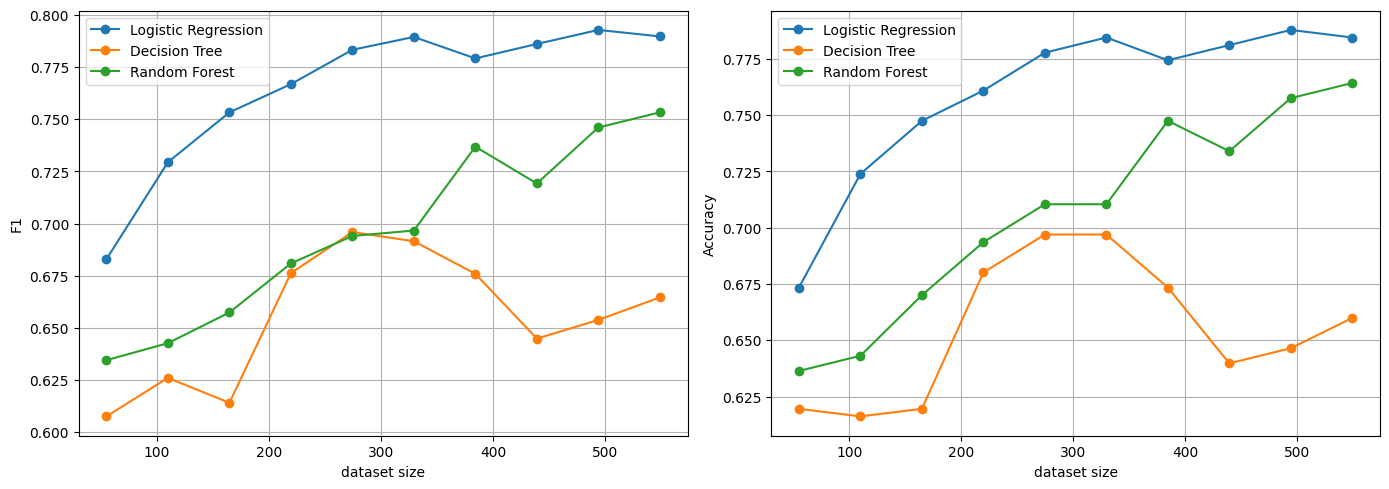

In [58]:
train_sizes = np.arange(1, 11) * len(X_train) / 10

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, scores in results.items():
    axes[0].plot(
        train_sizes,
        scores["f1"],
        label=name,
        marker="o"
    )

    axes[1].plot(
        train_sizes,
        scores["accuracy"],
        label=name,
        marker="o"
    )

axes[0].set_xlabel("dataset size")
axes[0].set_ylabel("F1")
axes[0].legend()
axes[0].grid()

axes[1].set_xlabel("dataset size")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

Как видно по графику логистической регрессии и дереву решений нет необходимости использовать всю обучающую выборку. В это же время случайный лес достиг лучшего качества на всём обучающем множестве, причём график демонстрирует тренд роста.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [60]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 33.9 MB/s  0:00:02


In [61]:
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, accuracy_score

n_estimators = list(range(10, 201, 10))

f1_scores = []
accuracy_scores = []

for n in n_estimators:
    model = CatBoostClassifier(
        iterations=n,
        learning_rate=0.05,
        depth=5,
        loss_function="MultiClass",
        random_seed=42,
        verbose=False
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test).ravel()

    f1_scores.append(
        f1_score(y_test, y_pred, average="macro")
    )
    accuracy_scores.append(
        accuracy_score(y_test, y_pred)
    )

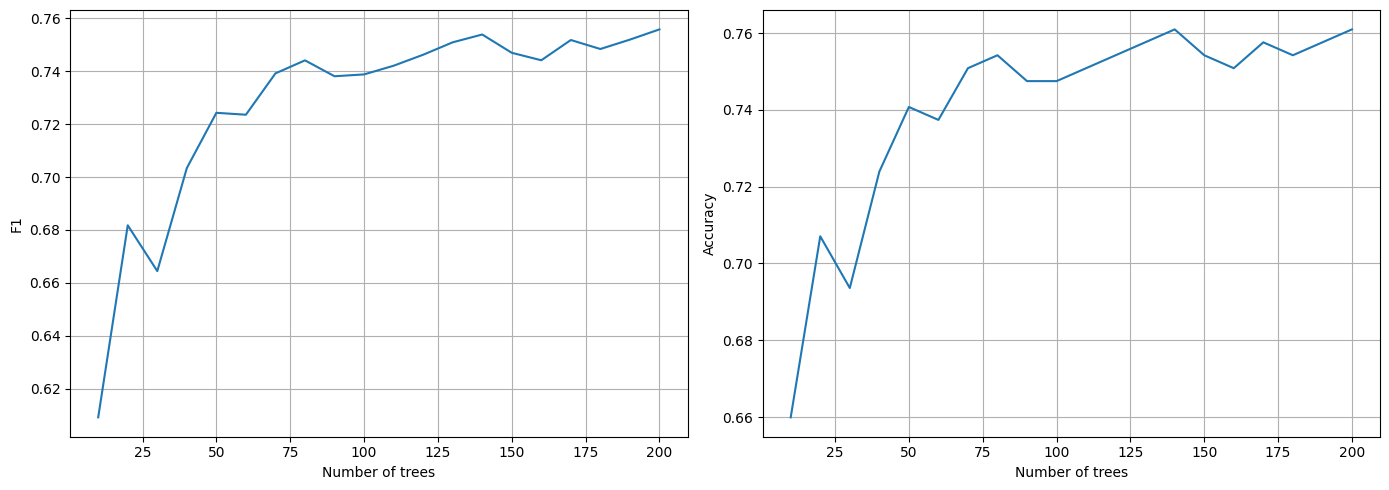

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    n_estimators,
    f1_scores,
)
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("F1")
axes[0].grid()

axes[1].plot(
    n_estimators,
    accuracy_scores,
)
axes[1].set_xlabel("Number of trees")
axes[1].set_ylabel("Accuracy")
axes[1].grid()

plt.tight_layout()
plt.show()

In [64]:
best_f1_idx = np.argmax(f1_scores)
best_acc_idx = np.argmax(accuracy_scores)

print(f"Optimum trees number by f1 score: {n_estimators[best_f1_idx]}")
print(f"Optimum trees number by accuracy: {n_estimators[best_acc_idx]}")

Optimum trees number by f1 score: 200
Optimum trees number by accuracy: 140


Оптимальное количество деревьев согласно f1 score - 200, в то время как согласно accuracy - 140.